# Mini Projects 1: Document Scanner, Colour Tracker and Motion Detector

Three complete, classic OpenCV projects that combine everything from the earlier notebooks. Each project follows the same professional pattern: load or generate input, build the processing pipeline step by step, and produce a measurable result. All inputs are generated or taken from the assets folder, so the projects run anywhere.

## Setup

We import OpenCV (`cv2`), NumPy and Matplotlib. In these notebooks images are displayed with Matplotlib so the code runs everywhere, including servers without a screen. The classic OpenCV window functions are explained where they belong, with example code you can run on your own machine.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)

def show(image, title="", cmap=None):
    """Display a BGR (or single-channel) image with matplotlib - works in any environment."""
    if len(image.shape) == 2:
        plt.imshow(image, cmap=cmap or "gray")
    else:
        plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()


OpenCV version: 4.10.0


## Project 1 - Document scanner: find the page

A scanner pipeline is: grayscale -> blur -> Canny edges -> find the largest 4-corner contour -> perspective warp (notebook 03). Step 1 finds the page outline in `document.png`.

Page contour found: True


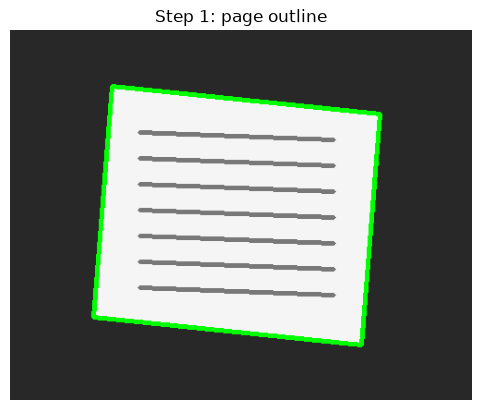

In [2]:
doc = cv2.imread("../assets/document.png")
gray = cv2.cvtColor(doc, cv2.COLOR_BGR2GRAY)
edges = cv2.Canny(cv2.GaussianBlur(gray, (5, 5), 0), 50, 150)
cs, _ = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
page = None
for c in sorted(cs, key=cv2.contourArea, reverse=True):
    approx = cv2.approxPolyDP(c, 0.02 * cv2.arcLength(c, True), True)
    if len(approx) == 4:
        page = approx
        break
print("Page contour found:", page is not None)
outlined = doc.copy()
if page is not None:
    cv2.drawContours(outlined, [page], -1, (0, 255, 0), 3)
show(outlined, "Step 1: page outline")

## Project 1 - Document scanner: flatten and clean

Order the four corners (top-left, top-right, bottom-right, bottom-left), warp to a rectangle, then adaptive-threshold to get the clean black-on-white scan look.

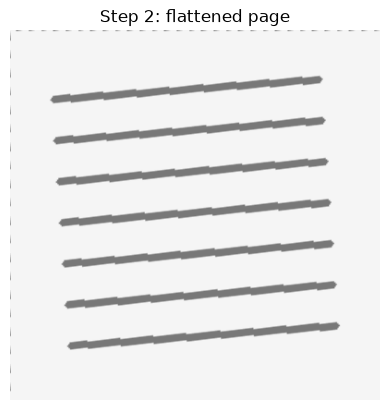

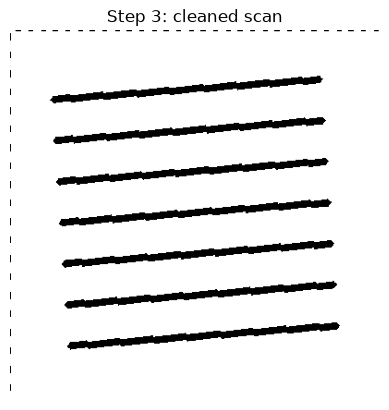

In [3]:
def order_points(pts):
    pts = pts.reshape(4, 2).astype(np.float32)
    ordered = np.zeros((4, 2), np.float32)
    s, d = pts.sum(axis=1), np.diff(pts, axis=1).ravel()
    ordered[0] = pts[np.argmin(s)]   # top-left
    ordered[2] = pts[np.argmax(s)]   # bottom-right
    ordered[1] = pts[np.argmin(d)]   # top-right
    ordered[3] = pts[np.argmax(d)]   # bottom-left
    return ordered

ordered = order_points(page)
M = cv2.getPerspectiveTransform(ordered, np.float32([[0, 0], [400, 0], [400, 400], [0, 400]]))
flat = cv2.warpPerspective(doc, M, (400, 400))
scan = cv2.adaptiveThreshold(cv2.cvtColor(flat, cv2.COLOR_BGR2GRAY), 255,
                             cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 21, 12)
show(flat, "Step 2: flattened page")
show(scan, "Step 3: cleaned scan")

## Project 2 - Colour tracker: mask and centroid per frame

The tracker from notebook 04, run over a synthetic sequence: HSV mask for red, morphology clean-up, moments centroid - repeated per frame to produce a trajectory. On a webcam this same loop tracks a real coloured object live.

In [4]:
frames = []
for i in range(20):
    f = np.full((240, 320, 3), 245, np.uint8)
    cv2.circle(f, (30 + i * 13, 60 + i * 6), 20, (0, 0, 255), -1)  # moving red ball
    frames.append(f)

def track_red(frame):
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    mask = cv2.inRange(hsv, np.array([0, 120, 70]), np.array([10, 255, 255])) + \
           cv2.inRange(hsv, np.array([170, 120, 70]), np.array([179, 255, 255]))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    m = cv2.moments(mask)
    return (int(m["m10"] / m["m00"]), int(m["m01"] / m["m00"])) if m["m00"] else None

trajectory = [track_red(f) for f in frames]
print("First 5 centroids:", trajectory[:5])
print("Last centroid:", trajectory[-1])

First 5 centroids: [(30, 60), (43, 66), (56, 72), (69, 78), (82, 84)]
Last centroid: (277, 174)


## Project 2 - Colour tracker: draw the trail

Drawing the centroid history as a polyline visualises the path - the output every tracking demo shows. Missing detections (None) must be skipped, which real sequences with occlusion will produce.

Tracked in 20 of 20 frames


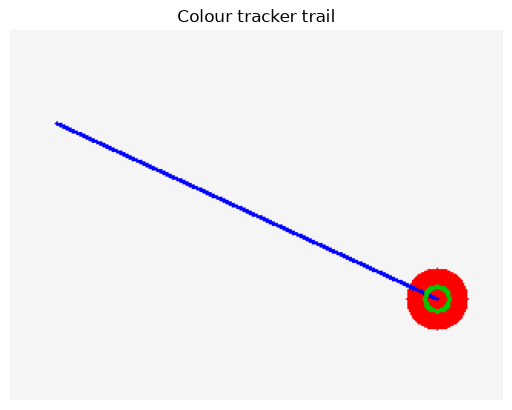

In [5]:
canvas = frames[-1].copy()
valid = [p for p in trajectory if p is not None]
for a, b in zip(valid, valid[1:]):
    cv2.line(canvas, a, b, (255, 0, 0), 2)
cv2.circle(canvas, valid[-1], 8, (0, 200, 0), 2)
print("Tracked in", len(valid), "of", len(frames), "frames")
show(canvas, "Colour tracker trail")

## Project 3 - Motion detector: frame differencing

The simplest motion detector compares consecutive frames: absolute difference -> grayscale -> blur -> threshold -> dilate. Any large white region means something moved. It needs a static camera, like background subtraction, but no learning period.

Motion pixels, identical frames: 0
Motion pixels, ball moved:       3426


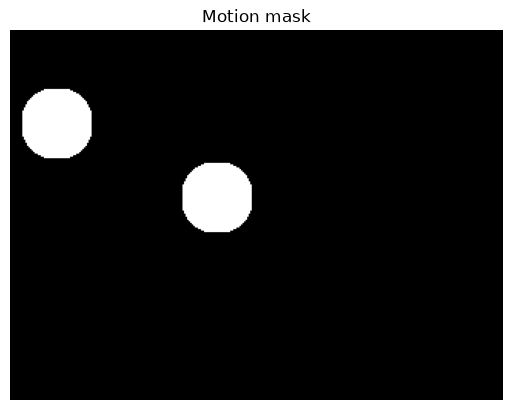

In [6]:
def motion_mask(f1, f2):
    diff = cv2.absdiff(f1, f2)
    g = cv2.GaussianBlur(cv2.cvtColor(diff, cv2.COLOR_BGR2GRAY), (5, 5), 0)
    _, m = cv2.threshold(g, 30, 255, cv2.THRESH_BINARY)
    return cv2.dilate(m, np.ones((3, 3), np.uint8), iterations=2)

still_a = frames[0]
still_b = frames[0].copy()
moved = frames[8]
print("Motion pixels, identical frames:", int((motion_mask(still_a, still_b) > 0).sum()))
print("Motion pixels, ball moved:      ", int((motion_mask(frames[0], moved) > 0).sum()))
show(motion_mask(frames[0], moved), "Motion mask")

## Project 3 - Motion detector: alarm logic

A detector becomes useful with a decision rule: motion area above a threshold for several frames in a row triggers an event. Counting per-frame motion over the whole sequence shows the rule working - and shows why a single-frame trigger would be noisy.

In [7]:
areas = [int((motion_mask(frames[i], frames[i + 1]) > 0).sum()) for i in range(len(frames) - 1)]
events = [i for i, a in enumerate(areas) if a > 500]
print("Per-frame motion areas:", areas)
print("Frames flagged as motion events (area > 500):", len(events), "of", len(areas))

Per-frame motion areas: [1974, 1974, 1974, 1974, 1974, 1974, 1974, 1974, 1974, 1974, 1974, 1974, 1974, 1974, 1974, 1974, 1974, 1974, 1974]
Frames flagged as motion events (area > 500): 19 of 19


## Key Points

- Document scanner = edges -> largest 4-corner contour -> ordered warp -> adaptive threshold.
- Corner ordering (sum/difference trick) is required before getPerspectiveTransform.
- Colour tracker = HSV mask + morphology + moments centroid, repeated per frame.
- Always handle missed detections (no centroid) in tracking loops.
- Frame differencing detects motion with a static camera and no training period.
- Alarm rules need area thresholds and persistence, not single noisy frames.

## Mini Task

1. Scanner: change the Canny thresholds to (20, 60) and check the page is still found.
2. Tracker: make the ball green, adjust the HSV range, and print the new trajectory.
3. Motion: add a second moving object and verify both appear in the motion mask area count.